# Praktik Terpadu YOLO (RET503) — Pj1 Perception System
**Jonathan Adis Pratama — NIM 4222401018**

Tugas: mendeteksi dua kelas objek (`panah`, `huruf_angka`) dengan YOLOv8n dan membandingkan tiga eksperimen:
**E1** pretrained · **E2** dari nol (tanpa transfer learning) · **E3** tuning `imgsz=640`.

Alur notebook: (1) siapkan dataset → (2) cek dataset → (3) ubah ke struktur `images/` + `labels/` → (4) jalankan skrip `06_latih_bandingkan.py` → (5) lihat grafik → (6) kumpulkan hasil.

## 1. Siapkan dataset
Unzip `dataset_gabungan_panah_hurufangka.zip` (2 kelas: `panah`=0, `huruf_angka`=1; split train/valid/test).

In [11]:
!rm -rf dataset_gabungan
!unzip -q dataset_gabungan_panah_hurufangka.zip -d dataset_gabungan
!ls dataset_gabungan
!ls dataset_gabungan/train/images | wc -l


data.yaml  test  train	valid
732


## 2. Cek dataset
Jumlah gambar dan objek per kelas di tiap split, serta 12 gambar sampel dengan kotaknya (untuk memastikan label benar).

Split    Gambar |  Gambar panah  Gambar huruf_angka |  Objek panah  Objek huruf_angka
train       732 |           366                 366 |          367                569
valid       162 |            81                  81 |           81                124
test        100 |            50                  50 |           50                 70
Total gambar: 994


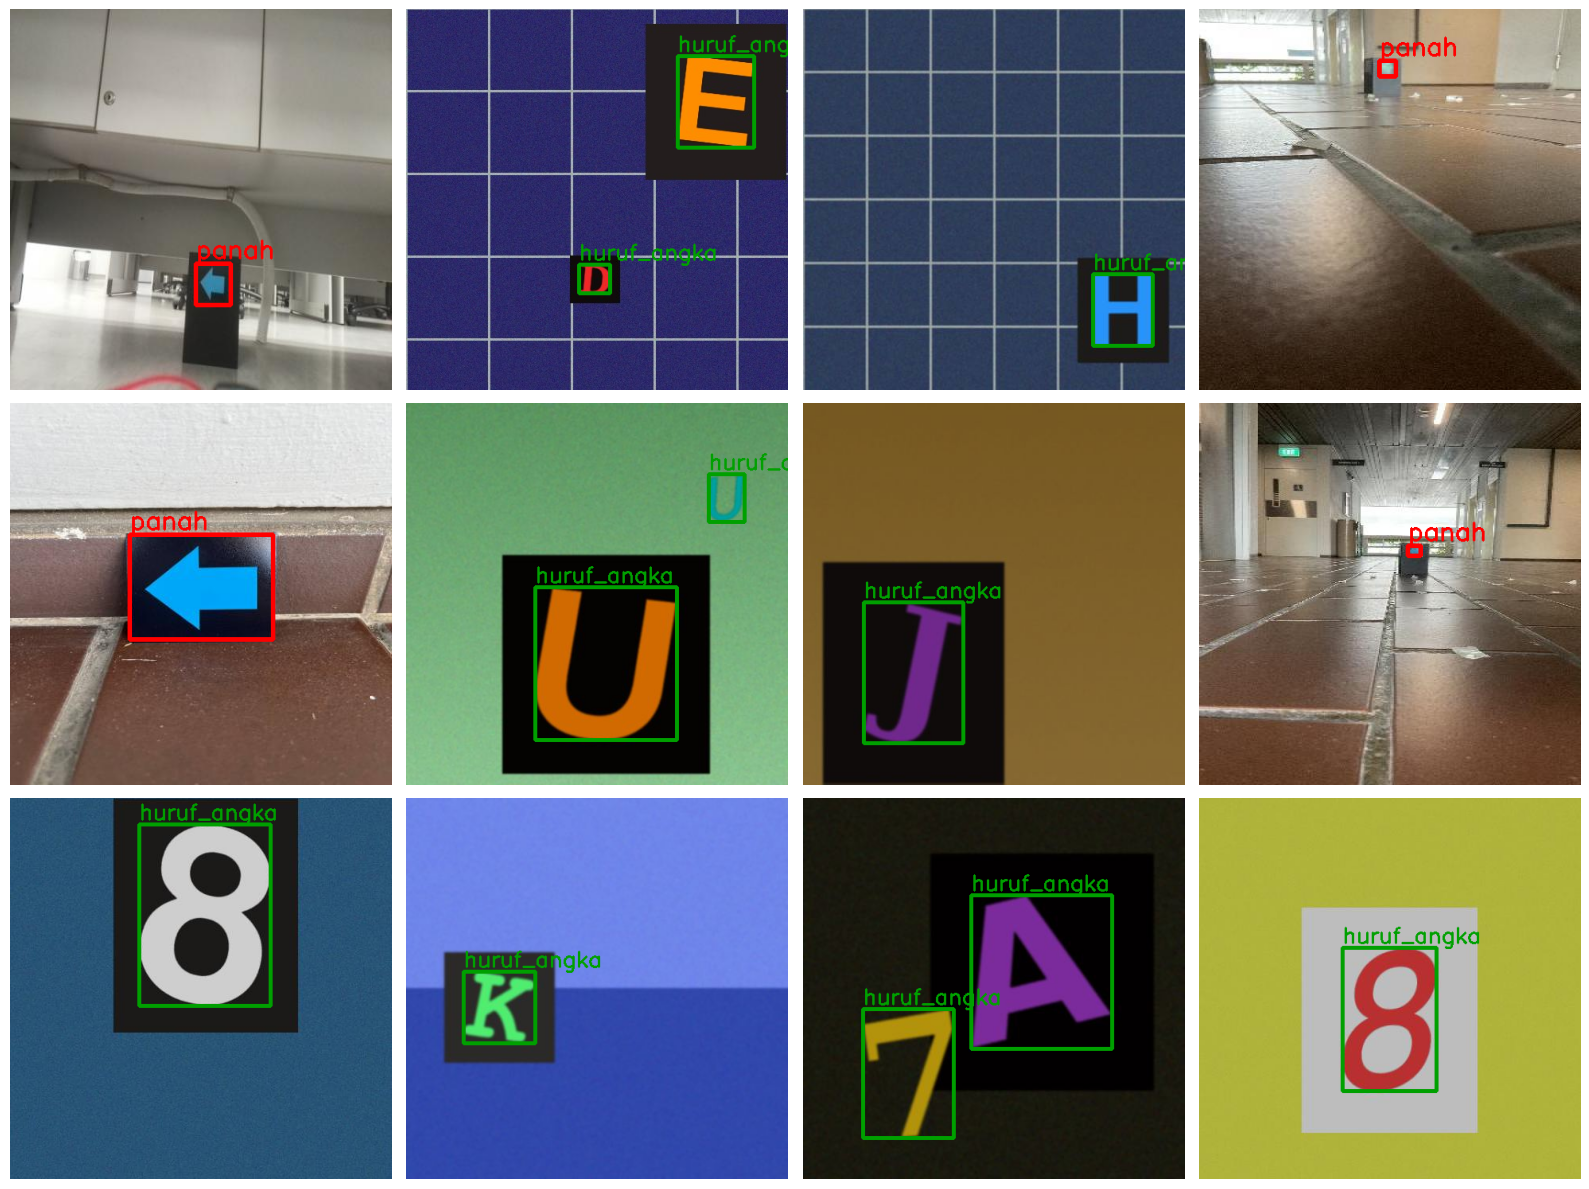

In [26]:
%matplotlib inline
import cv2, glob, random
from collections import Counter
import matplotlib.pyplot as plt

ROOT = "/content/dataset_gabungan"
NAMA = ["panah", "huruf_angka"]
WARNA = [(255, 0, 0), (0, 160, 0)]

# ---------- 1) Jumlah per kelas di setiap split ----------
print(f"{'Split':<7}{'Gambar':>8} | {'Gambar panah':>13}{'Gambar huruf_angka':>20} | {'Objek panah':>12}{'Objek huruf_angka':>19}")
total_img = 0
for split in ["train", "valid", "test"]:
    n_img = len(glob.glob(f"{ROOT}/{split}/images/*"))
    obj, img_per_kelas = Counter(), Counter()
    for f in glob.glob(f"{ROOT}/{split}/labels/*.txt"):
        kelas_di_gambar = set()
        for line in open(f).read().strip().splitlines():
            c = int(line.split()[0]); obj[c] += 1; kelas_di_gambar.add(c)
        for c in kelas_di_gambar: img_per_kelas[c] += 1
    total_img += n_img
    print(f"{split:<7}{n_img:>8} | {img_per_kelas[0]:>13}{img_per_kelas[1]:>20} | {obj[0]:>12}{obj[1]:>19}")
print("Total gambar:", total_img)

# ---------- 2) Gambar sampel train dengan kotak dan nama kelas ----------
semua = glob.glob(f"{ROOT}/train/images/*")
fig, ax = plt.subplots(3, 4, figsize=(16, 12))
for a, p in zip(ax.ravel(), random.sample(semua, 12)):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    lbl = p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    for line in open(lbl).read().strip().splitlines():
        c, cx, cy, bw, bh = line.split(); c = int(c); cx, cy, bw, bh = map(float, (cx, cy, bw, bh))
        x0, y0 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)
        x1, y1 = int((cx + bw / 2) * w), int((cy + bh / 2) * h)
        cv2.rectangle(im, (x0, y0), (x1, y1), WARNA[c], 3)
        cv2.putText(im, NAMA[c], (x0, max(y0 - 6, 14)), 0, 0.9, WARNA[c], 2)
    a.imshow(im); a.axis("off")
plt.tight_layout()
plt.savefig("cek_dataset.png", dpi=80)
plt.show()

## 3. Ubah ke struktur yang diminta skrip
`train/valid/test` → `images/{train,val,test}` + `labels/{train,val,test}`, lalu buat `data.yaml` dan `classes.txt` di `/content/dataset_v1`.

In [27]:
import os, glob, shutil
SRC, DST = "/content/dataset_gabungan", "/content/dataset_v1"
peta = {"train": "train", "valid": "val", "test": "test"}
for s_lama, s_baru in peta.items():
    os.makedirs(f"{DST}/images/{s_baru}", exist_ok=True)
    os.makedirs(f"{DST}/labels/{s_baru}", exist_ok=True)
    for f in glob.glob(f"{SRC}/{s_lama}/images/*"):
        shutil.copy(f, f"{DST}/images/{s_baru}/")
    for f in glob.glob(f"{SRC}/{s_lama}/labels/*.txt"):
        shutil.copy(f, f"{DST}/labels/{s_baru}/")

kelas = ["panah", "huruf_angka"]
open(f"{DST}/classes.txt", "w").write("\n".join(kelas) + "\n")
open(f"{DST}/data.yaml", "w").write(
    f"path: {DST}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n" +
    "".join(f"  {i}: {k}\n" for i, k in enumerate(kelas)))
!ls /content/dataset_v1/images/train | wc -l

732


## 4. Siapkan skrip praktik
Unzip `YOLO.zip` (skrip 00–06 dari dosen).

In [31]:
!unzip -q YOLO.zip -d YOLO_skrip
%cd /content/YOLO_skrip/YOLO/YOLO

/content/YOLO_skrip/YOLO/YOLO


## 5. Latih E1, E2, E3 dan bandingkan
`06_latih_bandingkan.py` melatih ketiga eksperimen dengan pengaturan sama (yolov8n, 50 epoch, imgsz 320, batch 16, seed 0). Hanya E2 (tanpa bobot pretrained) dan E3 (`imgsz=640`) yang sengaja diubah. Model terbaik dipilih dari **mAP50-95 data val**, lalu diuji **sekali** pada data test. Hasil tersimpan di `hasil_praktik_4222401018.txt` dan `.csv`.

In [32]:
!pip install -q ultralytics
!python 06_latih_bandingkan.py --nim 4222401018 --nama "Jonathan Adis Pratama" \
    --data /content/dataset_v1/data.yaml --model yolov8n \
    --epochs 50 --imgsz 320 --ubah imgsz=640


=== E1_pretrained: yolov8n.pt | pretrained=True | pengaturan dasar ===
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale

## 6. Grafik pelatihan tiap eksperimen

E1_pretrained


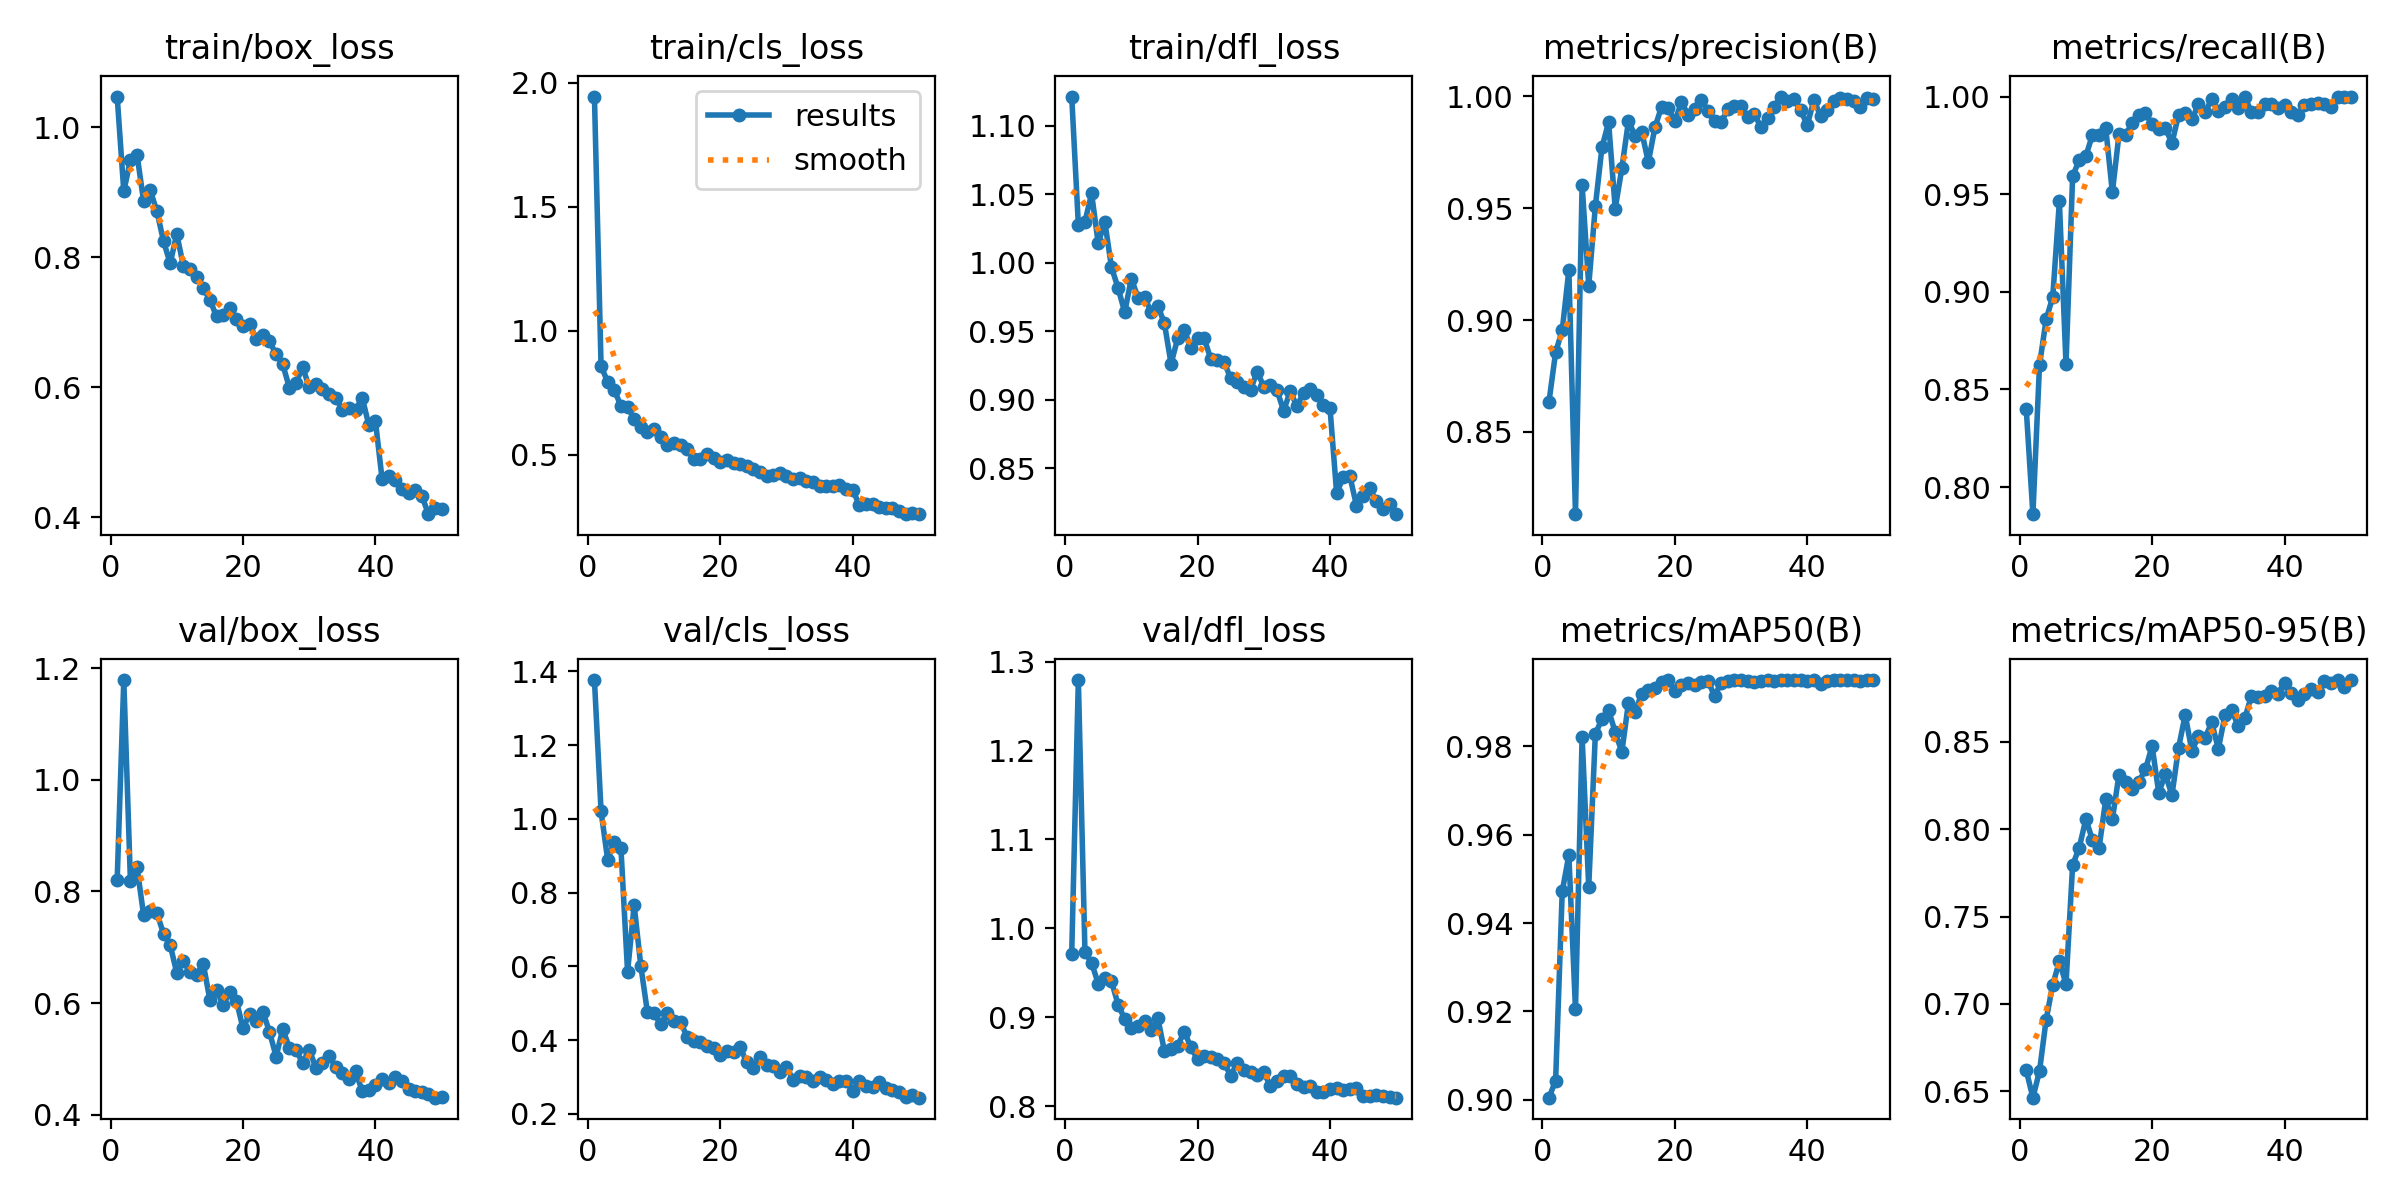

E2_scratch


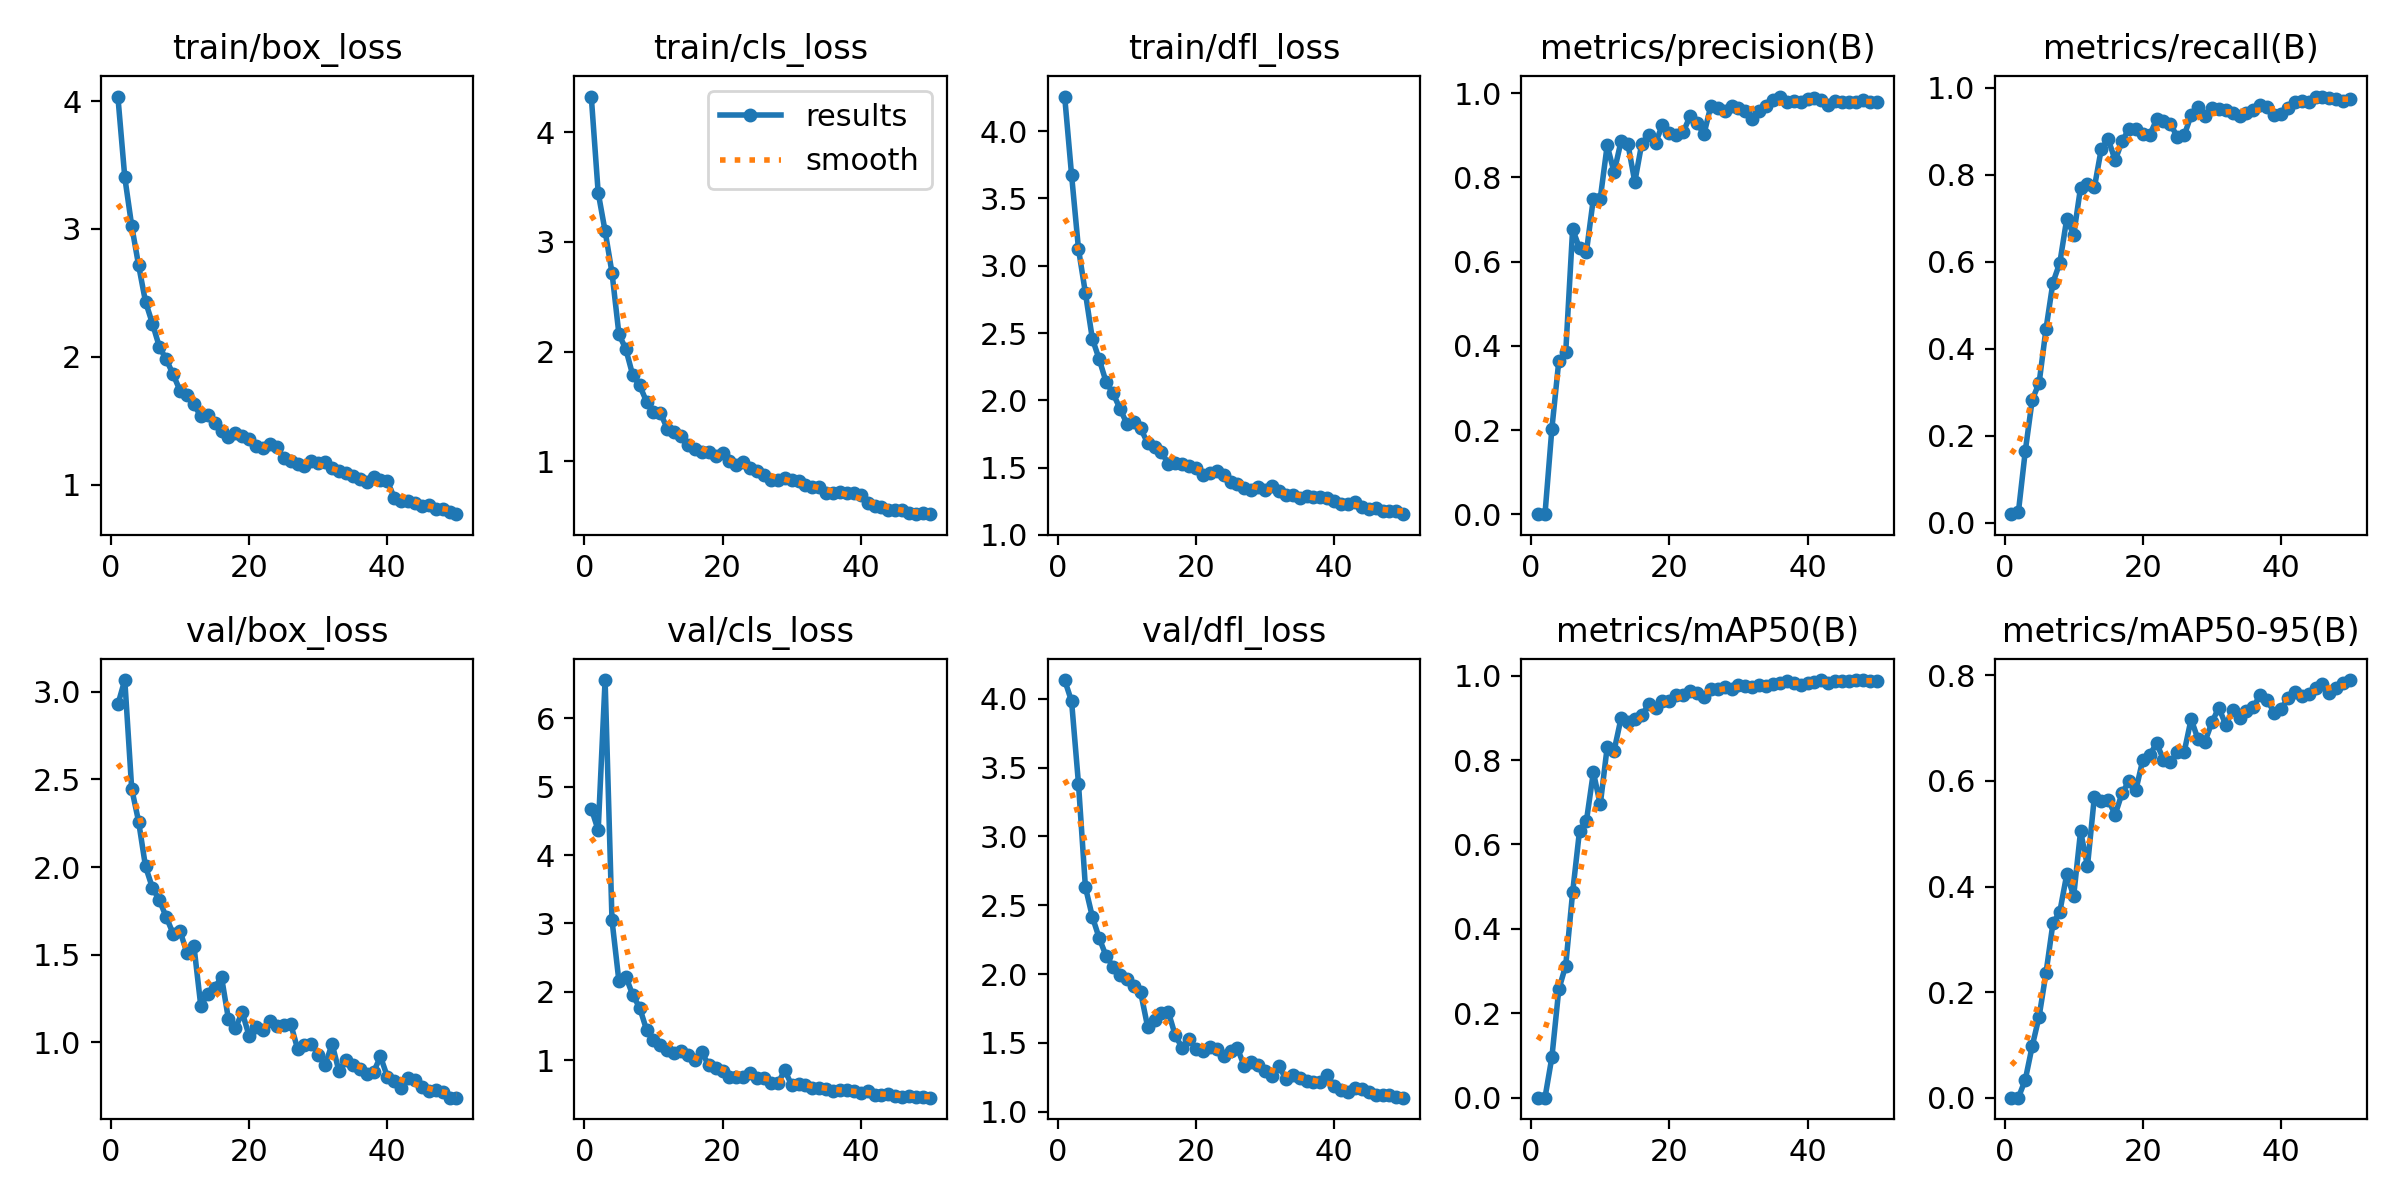

E3_tuning


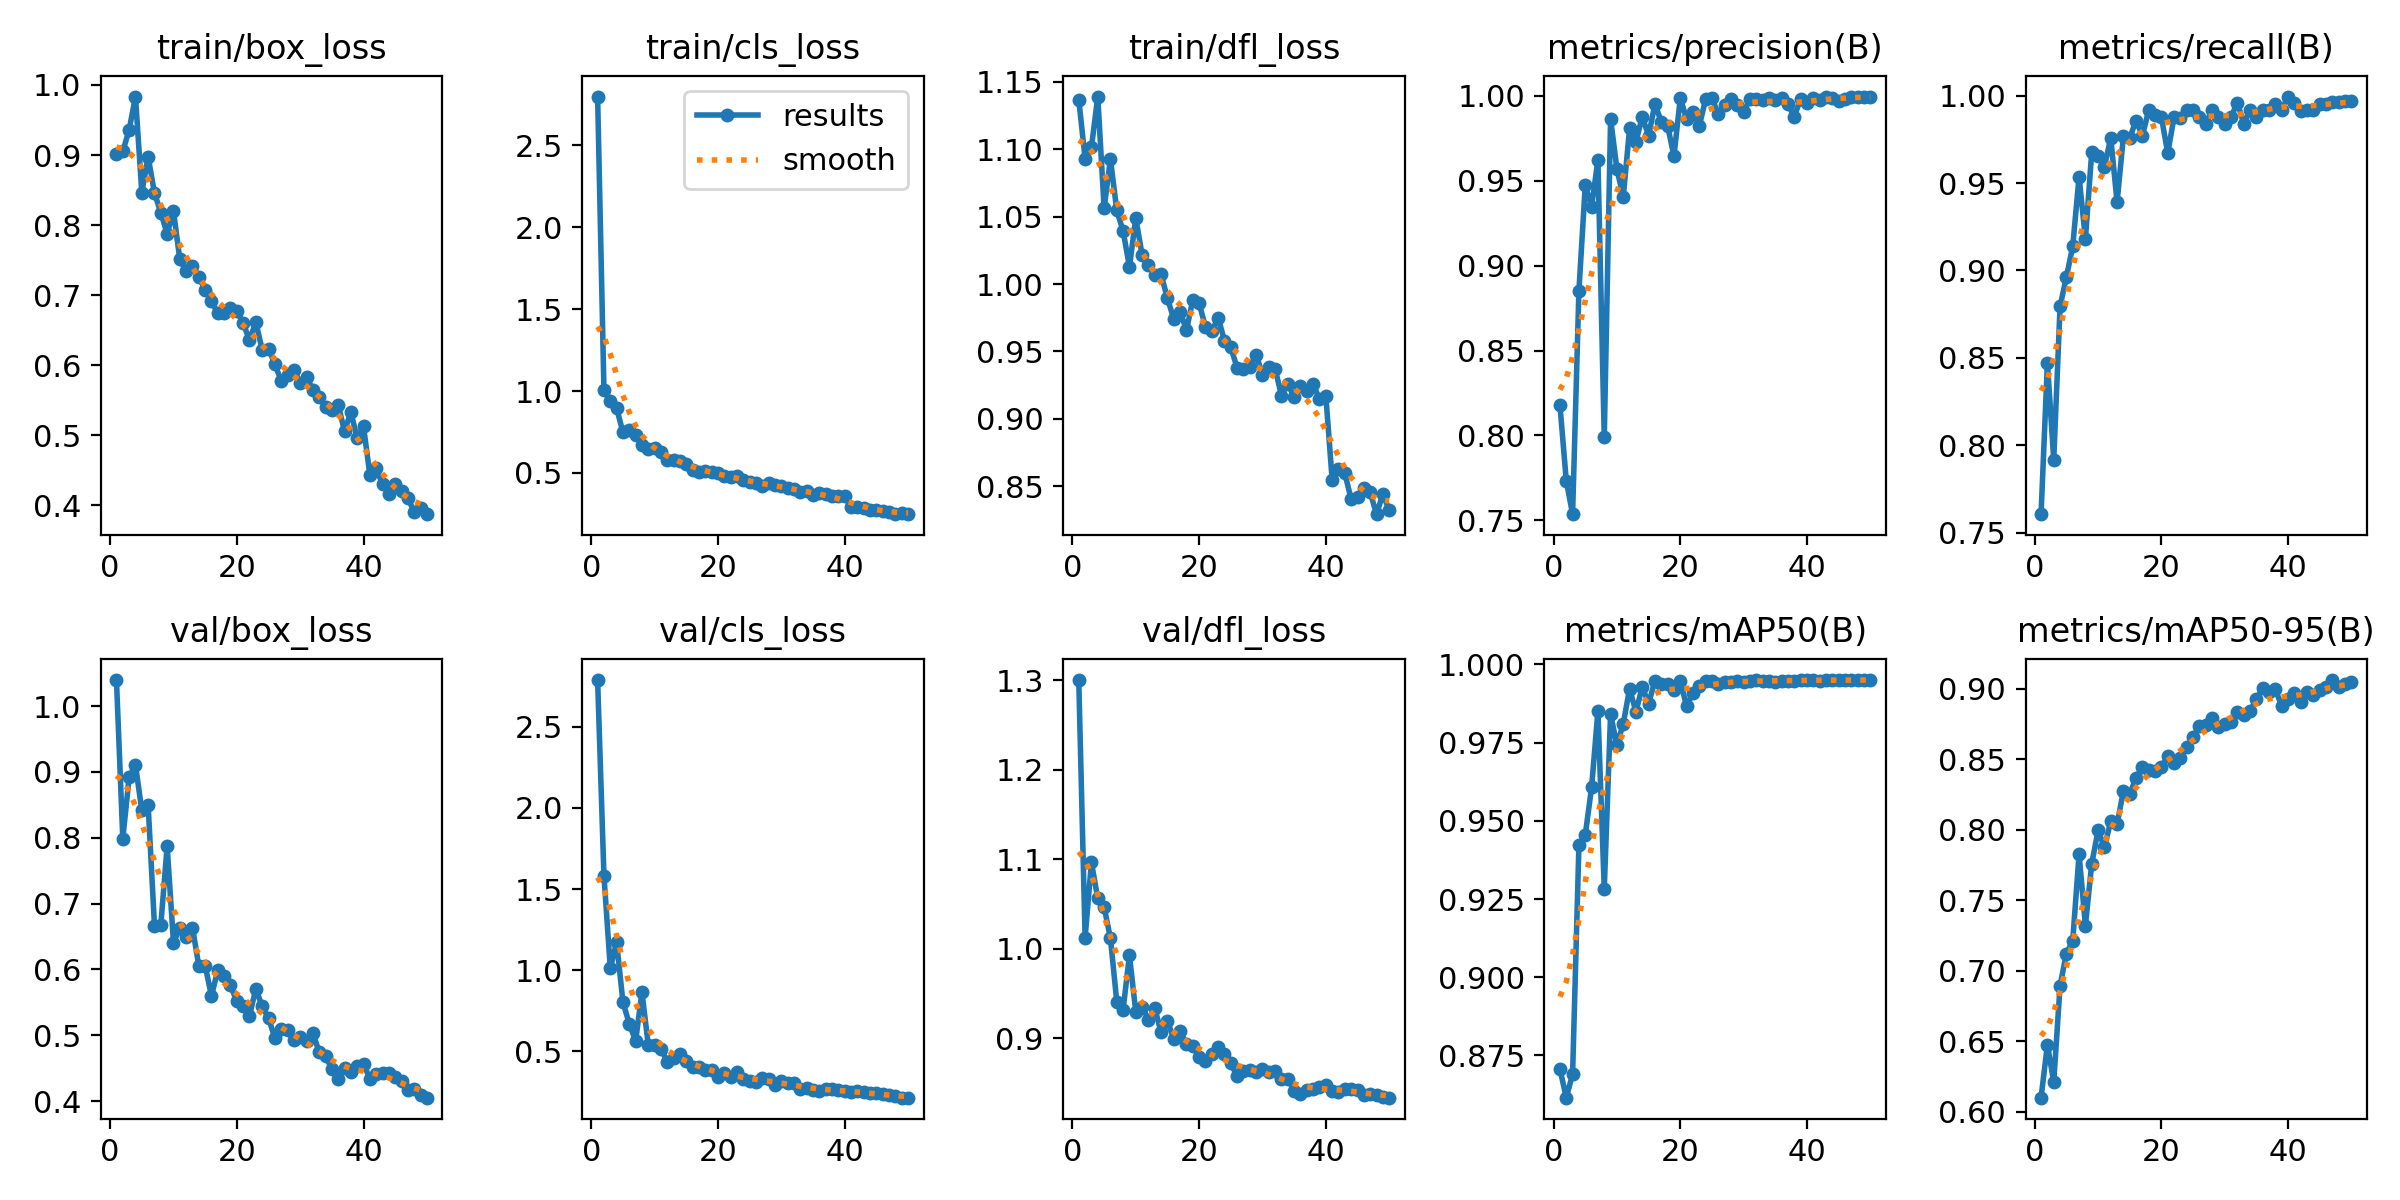

In [33]:
from IPython.display import Image, display
base = "/content/YOLO_skrip/YOLO/YOLO/hasil_praktik"
for e in ["E1_pretrained", "E2_scratch", "E3_tuning"]:
    print(e)
    display(Image(f"{base}/{e}/results.png"))

## 6b. Confusion matrix E1, E2, E3 (data val)
Skrip praktik hanya menyimpan grafik `results.png`, jadi confusion matrix dibuat ulang dari bobot terbaik (`best.pt`) tiap eksperimen, **memakai data val saja** (data test tidak disentuh lagi). `imgsz` harus sama dengan saat latihan: 320 untuk E1 dan E2, 640 untuk E3. Ambang kepercayaan `conf=0.25`.

Cara baca tabel angka: **baris = kelas yang diprediksi, kolom = kelas sebenarnya**; `background` = tidak ada objek (baris `background` = objek yang terlewat, kolom `background` = kotak berlebih).

In [ ]:
import os, shutil
import pandas as pd
from ultralytics import YOLO
from IPython.display import Image, display

BASE = "/content/YOLO_skrip/YOLO/YOLO/hasil_praktik"
DATA = "/content/dataset_v1/data.yaml"
IMGSZ = {"E1_pretrained": 320, "E2_scratch": 320, "E3_tuning": 640}
NAMA = ["panah", "huruf_angka", "background"]

for e, sz in IMGSZ.items():
    bobot = f"{BASE}/{e}/weights/best.pt"
    assert os.path.exists(bobot), f"{bobot} tidak ada - jalankan dulu sel latihan (bagian 5)"
    r = YOLO(bobot).val(data=DATA, split="val", imgsz=sz, conf=0.25, plots=True,
                        project=f"{BASE}/{e}", name="cm_val", exist_ok=True, verbose=False)
    # simpan ke folder eksperimen supaya ikut ter-zip dan ikut tersalin ke repo_github
    for f in ["confusion_matrix.png", "confusion_matrix_normalized.png"]:
        shutil.copy(f"{BASE}/{e}/cm_val/{f}", f"{BASE}/{e}/{f}")
    m = r.confusion_matrix.matrix.astype(int)
    print(f"\n===== {e} (imgsz {sz}) - baris=prediksi, kolom=sebenarnya =====")
    display(pd.DataFrame(m, index=[f"pred_{n}" for n in NAMA], columns=[f"benar_{n}" for n in NAMA]))
    display(Image(f"{BASE}/{e}/confusion_matrix.png", width=520))

## 7. Kumpulkan hasil
Zip folder `hasil_praktik` beserta `.txt` dan `.csv` untuk dikumpulkan.

In [34]:
%cd /content/YOLO_skrip/YOLO/YOLO
!zip -qr hasil_praktik_4222401018.zip hasil_praktik hasil_praktik_4222401018.txt hasil_praktik_4222401018.csv

/content/YOLO_skrip/YOLO/YOLO


## 8. Siapkan folder untuk GitHub
Salin gambar yang dipakai README (grafik + confusion matrix model terpilih **E3_tuning**) ke folder `repo_github/`. Sel ini baru ditambahkan — jalankan setelah bagian 6b selesai, lalu unduh `repo_github.zip`.

In [ ]:
import os, shutil
BASE = "/content/YOLO_skrip/YOLO/YOLO"
OUT = "/content/repo_github"
for e in ["E1_pretrained", "E2_scratch", "E3_tuning"]:
    os.makedirs(f"{OUT}/{e}", exist_ok=True)
    for f in ["results.png", "confusion_matrix.png", "confusion_matrix_normalized.png"]:
        src = f"{BASE}/hasil_praktik/{e}/{f}"
        if os.path.exists(src):
            shutil.copy(src, f"{OUT}/{e}/{f}")
os.makedirs(f"{OUT}/gambar", exist_ok=True)
shutil.copy("/content/cek_dataset.png", f"{OUT}/gambar/cek_dataset.png")
for f in ["hasil_praktik_4222401018.txt", "hasil_praktik_4222401018.csv"]:
    shutil.copy(f"{BASE}/{f}", OUT)
!cd /content && zip -qr repo_github.zip repo_github && ls -R repo_github | head -40
